# DES Data Exploration

Explores the three datasets in `/mnt/c/Users/andre/DATA/`:

| File | Size | Description |
|------|------|-------------|
| `DESY3_metacal_v03-004.h5` | 291 GB | DES Y3 metacalibration shape catalog (399 M sources) |
| `y3_redmapper_v6.4.22+2_release.h5` | 328 MB | DES Y3 redMaPPer cluster catalog (21 k clusters) |
| `y6a2_dnf_wazp_v5.0.12.6801_clusters.fits` | 76 MB | DES Y6 WaZP cluster catalog (417 k clusters) |
| `y6a2_dnf_wazp_v5.0.12.6801_members.fits` | 1 GB | DES Y6 WaZP cluster member catalog |
| `y6a2_dnf_wazp_v5.0.12.6801_footprint.fits` | 515 MB | DES Y6 HEALPix survey footprint |

References:
- Shape catalog: https://des.ncsa.illinois.edu/releases/y3a2/Y3key-catalogs
- WaZP clusters: https://des.ncsa.illinois.edu/releases/y6a2/Y6cluster-wazp

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import h5py
import time
from astropy.io import fits
import warnings
warnings.filterwarnings('ignore')

DATA = '/mnt/c/Users/andre/DATA'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

---
## 1 — DES Y6 WaZP Cluster Catalog

WaZP (Wavelet Z Photometric) is a photometric cluster finder applied to the DES Y6 gold catalog
using DNF photo-z estimates. The cluster catalog contains 416,947 detections over 0 < z < 1.32.

**Richness** (`NGALS`) is the weighted count of member galaxies within the cluster radius.
**SNR** is the cluster detection significance.

In [2]:
# ── Load cluster catalog ────────────────────────────────────────────────────
with fits.open(f'{DATA}/y6a2_dnf_wazp_v5.0.12.6801_clusters.fits', memmap=True) as h:
    cl = h[1].data.copy()

print(f'Clusters: {len(cl):,}')
print(f'\nColumns:')
for name in cl.dtype.names:
    arr = cl[name]
    if arr.dtype.kind in 'fiu':
        print(f'  {name:30s}  {arr.dtype}  [{arr.min():.4g}, {arr.max():.4g}]')
    else:
        print(f'  {name:30s}  {arr.dtype}  (string)')

Clusters: 416,947

Columns:
  NAME                            <U31  (string)
  ID                              >i8  [1, 4.169e+05]
  RA                              >f8  [0.0004491, 360]
  DEC                             >f8  [-67.39, 5.369]
  ZPHOT                           >f4  [0.0267, 1.317]
  ZSPEC                           >f8  [nan, nan]
  ZSPEC_UNC                       >f8  [nan, nan]


  ZSPEC_TYPE                      <U7  (string)
  SNR                             >f4  [3, 31.6]
  NGALS                           >f8  [5, 308.8]
  NGALS_UNC                       >f4  [1.581, 14.39]
  RADIUS_MPC                      >f4  [0.16, 2.5]
  RADIUS_AMIN                     >f4  [0.3201, 31.52]
  COVER_FRAC_1MPC                 >f8  [0.1675, 1]
  COVER_FRAC_1MPC_WEIGHTED        >f8  [0.1653, 1]
  ID_CG                           >i8  [-1, 1.701e+09]
  RA_CG                           >f8  [nan, nan]
  DEC_CG                          >f8  [nan, nan]
  IN_COSMO                        bool  (string)
  SZE_ACT_ID                      <U19  (string)


  SZE_SPT_ID                      <U16  (string)
  SZE_SPT_SOURCE                  <U9  (string)


In [3]:
# Column descriptions (WaZP Y6 release)
col_desc = {
    'NAME':                     'Cluster name  (WAZP DES Y6 J<RA><DEC>)',
    'ID':                       'Unique cluster identifier (int64)',
    'RA':                       'Right Ascension of cluster centre [deg]',
    'DEC':                      'Declination of cluster centre [deg]',
    'ZPHOT':                    'Photometric redshift of cluster (DNF)',
    'ZSPEC':                    'Spectroscopic redshift of brightest galaxy (BCG), if available',
    'ZSPEC_UNC':                'Uncertainty on ZSPEC',
    'ZSPEC_TYPE':               'Source of spectroscopic redshift',
    'SNR':                      'Detection signal-to-noise ratio',
    'NGALS':                    'Richness — weighted number of member galaxies',
    'NGALS_UNC':                'Uncertainty on richness',
    'RADIUS_MPC':               'Cluster detection radius [Mpc]',
    'RADIUS_AMIN':              'Cluster detection radius [arcmin]',
    'COVER_FRAC_1MPC':          'Survey coverage fraction within 1 Mpc',
    'COVER_FRAC_1MPC_WEIGHTED': 'Weighted survey coverage fraction within 1 Mpc',
    'ID_CG':                    'Identifier of the central galaxy (BCG candidate)',
    'RA_CG':                    'RA of the central galaxy [deg]',
    'DEC_CG':                   'Dec of the central galaxy [deg]',
    'IN_COSMO':                 'Flag: cluster passes cosmological sample cuts',
    'SZE_ACT_ID':               'Cross-match ID from ACT SZ catalog',
    'SZE_SPT_ID':               'Cross-match ID from SPT SZ catalog',
    'SZE_SPT_SOURCE':           'SPT source type string',
}
print(f'{"Column":<30}  Description')
print('-' * 80)
for k, v in col_desc.items():
    print(f'{k:<30}  {v}')

Column                          Description
--------------------------------------------------------------------------------
NAME                            Cluster name  (WAZP DES Y6 J<RA><DEC>)
ID                              Unique cluster identifier (int64)
RA                              Right Ascension of cluster centre [deg]
DEC                             Declination of cluster centre [deg]
ZPHOT                           Photometric redshift of cluster (DNF)
ZSPEC                           Spectroscopic redshift of brightest galaxy (BCG), if available
ZSPEC_UNC                       Uncertainty on ZSPEC
ZSPEC_TYPE                      Source of spectroscopic redshift
SNR                             Detection signal-to-noise ratio
NGALS                           Richness — weighted number of member galaxies
NGALS_UNC                       Uncertainty on richness
RADIUS_MPC                      Cluster detection radius [Mpc]
RADIUS_AMIN                     Cluster detection radi

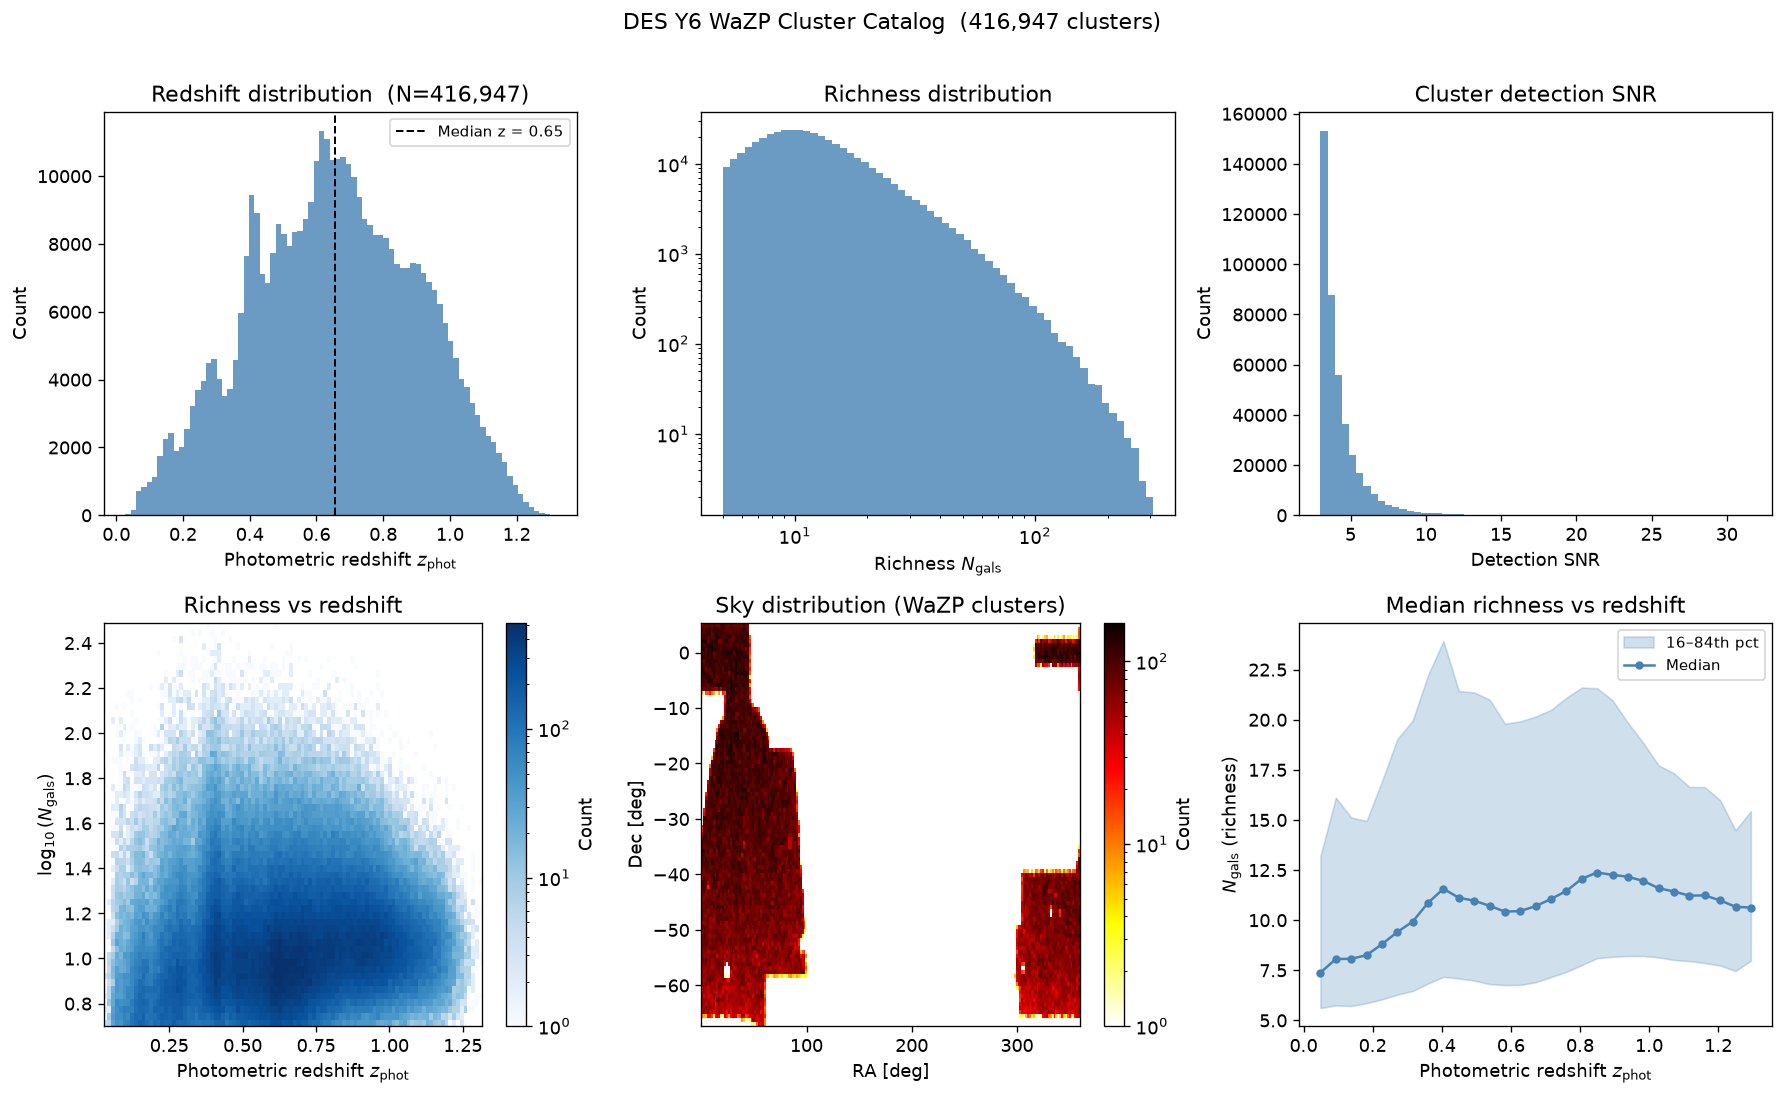

In [4]:
# ── Cluster statistics plots ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

z   = cl['ZPHOT']
ngals = cl['NGALS']
snr = cl['SNR']

# 1. Redshift distribution
ax = axes[0, 0]
ax.hist(z, bins=80, color='steelblue', edgecolor='none', alpha=0.8)
ax.set_xlabel('Photometric redshift $z_{\\rm phot}$')
ax.set_ylabel('Count')
ax.set_title(f'Redshift distribution  (N={len(cl):,})')
ax.axvline(np.median(z), color='k', ls='--', lw=1.2, label=f'Median z = {np.median(z):.2f}')
ax.legend(fontsize=9)

# 2. Richness distribution (log scale)
ax = axes[0, 1]
ax.hist(ngals, bins=np.logspace(np.log10(5), np.log10(310), 60),
        color='steelblue', edgecolor='none', alpha=0.8)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'Richness $N_{\rm gals}$')
ax.set_ylabel('Count')
ax.set_title('Richness distribution')

# 3. SNR distribution
ax = axes[0, 2]
ax.hist(snr, bins=60, color='steelblue', edgecolor='none', alpha=0.8)
ax.set_xlabel('Detection SNR')
ax.set_ylabel('Count')
ax.set_title('Cluster detection SNR')

# 4. Richness vs redshift scatter (2D histogram)
ax = axes[1, 0]
h2d, xe, ye, img = ax.hist2d(
    z, np.log10(ngals),
    bins=[100, 60], cmap='Blues',
    norm=mcolors.LogNorm(),
)
plt.colorbar(img, ax=ax, label='Count')
ax.set_xlabel('Photometric redshift $z_{\\rm phot}$')
ax.set_ylabel(r'$\log_{10}(N_{\rm gals})$')
ax.set_title('Richness vs redshift')

# 5. Sky distribution
ax = axes[1, 1]
h2d_sky, xe, ye, img2 = ax.hist2d(
    cl['RA'], cl['DEC'],
    bins=[200, 100], cmap='hot_r',
    norm=mcolors.LogNorm(),
)
plt.colorbar(img2, ax=ax, label='Count')
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.set_title('Sky distribution (WaZP clusters)')

# 6. Median richness per redshift bin
ax = axes[1, 2]
zbins = np.linspace(z.min(), z.max(), 30)
zmid  = 0.5 * (zbins[:-1] + zbins[1:])
med_ngals = [np.median(ngals[(z >= zbins[i]) & (z < zbins[i+1])]) for i in range(len(zmid))]
p84_ngals = [np.percentile(ngals[(z >= zbins[i]) & (z < zbins[i+1])], 84) for i in range(len(zmid))]
p16_ngals = [np.percentile(ngals[(z >= zbins[i]) & (z < zbins[i+1])], 16) for i in range(len(zmid))]
ax.fill_between(zmid, p16_ngals, p84_ngals, alpha=0.25, color='steelblue', label='16–84th pct')
ax.plot(zmid, med_ngals, 'o-', color='steelblue', ms=4, lw=1.5, label='Median')
ax.set_xlabel('Photometric redshift $z_{\\rm phot}$')
ax.set_ylabel(r'$N_{\rm gals}$ (richness)')
ax.set_title('Median richness vs redshift')
ax.legend(fontsize=9)

plt.suptitle('DES Y6 WaZP Cluster Catalog  (416,947 clusters)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('figs/wazp_cluster_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

### WaZP cluster sky distribution — Aitoff projection (healpy)

Separate from the panel grid above: bins clusters into a HEALPix map and
renders it in an Aitoff projection via `healpy.newvisufunc.projview`, saved
as its own PDF.

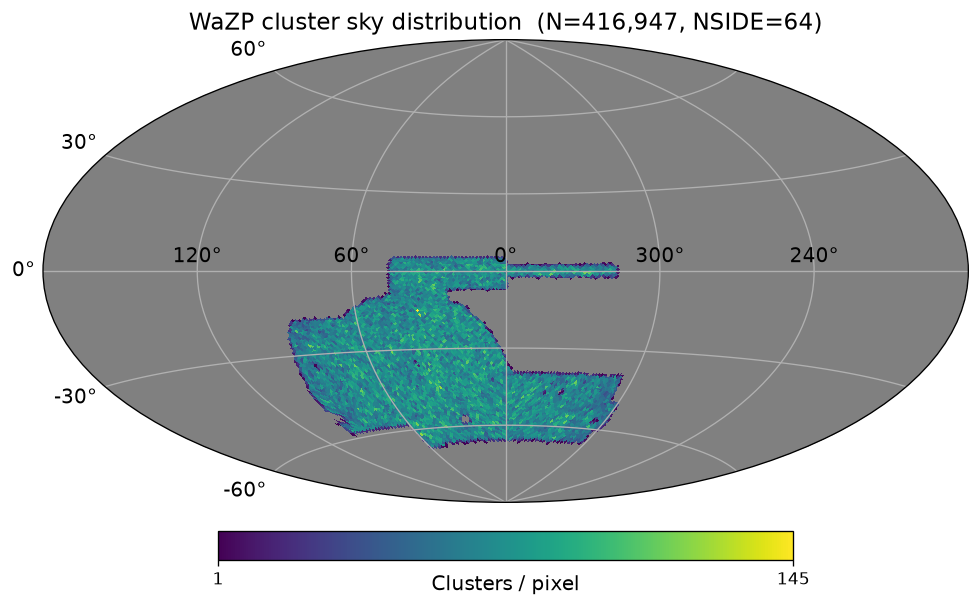

In [5]:
import healpy as hp
from healpy.newvisufunc import projview

NSIDE = 64
npix = hp.nside2npix(NSIDE)
theta = np.radians(90.0 - cl['DEC'])
phi   = np.radians(cl['RA'])
pix   = hp.ang2pix(NSIDE, theta, phi)
counts = np.bincount(pix, minlength=npix).astype(float)
counts[counts == 0] = np.nan  # unobserved/empty pixels shown as background, not zero

projview(
    counts,
    projection_type='aitoff',
    coord=['C'],
    graticule=True, graticule_labels=True,
    unit='Clusters / pixel',
    cmap='viridis',
    title=f'WaZP cluster sky distribution  (N={len(cl):,}, NSIDE={NSIDE})',
)
plt.savefig('figs/wazp_sky_aitoff.pdf', bbox_inches='tight')
plt.show()

In [6]:
# Cosmological sample subset
cosmo = cl[cl['IN_COSMO']]
print(f'Full catalog:         {len(cl):,} clusters')
print(f'IN_COSMO==True:       {len(cosmo):,} clusters  ({100*len(cosmo)/len(cl):.1f}%)')
print(f'Redshift range:       {cosmo["ZPHOT"].min():.3f} – {cosmo["ZPHOT"].max():.3f}')
print(f'Richness range:       {cosmo["NGALS"].min():.1f} – {cosmo["NGALS"].max():.1f}')
print(f'With SZE-ACT match:   {(cosmo["SZE_ACT_ID"] != "").sum():,}')
print(f'With SZE-SPT match:   {(cosmo["SZE_SPT_ID"] != "").sum():,}')

Full catalog:         416,947 clusters
IN_COSMO==True:       301,406 clusters  (72.3%)
Redshift range:       0.027 – 0.972
Richness range:       5.0 – 308.8
With SZE-ACT match:   1,376
With SZE-SPT match:   606


---
## 2 — DES Y6 WaZP Member Catalog

Each cluster member has a photometric membership probability (`PMEM`), 
five-band photometry (grizY), and optional spec-z.

In [7]:
with fits.open(f'{DATA}/y6a2_dnf_wazp_v5.0.12.6801_members.fits', memmap=True) as h:
    mem_cols = h[1].columns
    mem_data = h[1].data
    n_mem = len(mem_data)
    pmem_sample = mem_data['PMEM'][:5_000_000].copy()

print(f'Total member entries: {n_mem:,}')
print(f'\nColumns:')

mem_desc = {
    'ID':           'Unique galaxy identifier',
    'ID_CLUSTER':   'Parent cluster ID (links to cluster catalog)',
    'RA':           'Galaxy RA [deg]',
    'DEC':          'Galaxy Dec [deg]',
    'ZPHOT':        'Galaxy photometric redshift (DNF)',
    'ZSPEC':        'Galaxy spectroscopic redshift (if available)',
    'ZSPEC_SOURCE': 'Source of spectroscopic redshift',
    'PMEM':         'Membership probability [0, 1]',
    'FLAG_CG':      'True if this galaxy is the cluster central galaxy (BCG)',
    'MAG_G':        'Magnitude in g-band',
    'MAG_R':        'Magnitude in r-band',
    'MAG_I':        'Magnitude in i-band',
    'MAG_Z':        'Magnitude in z-band',
    'MAG_Y':        'Magnitude in Y-band',
}
for col in mem_cols:
    desc = mem_desc.get(col.name, '')
    print(f'  {col.name:20s}  {col.format:6s}  {col.unit or "":8s}  {desc}')

Total member entries: 13,133,244

Columns:
  ID                    K                 Unique galaxy identifier
  ID_CLUSTER            K                 Parent cluster ID (links to cluster catalog)
  RA                    D                 Galaxy RA [deg]
  DEC                   D                 Galaxy Dec [deg]
  ZPHOT                 E                 Galaxy photometric redshift (DNF)
  ZSPEC                 D                 Galaxy spectroscopic redshift (if available)
  ZSPEC_SOURCE          11A               Source of spectroscopic redshift
  PMEM                  E                 Membership probability [0, 1]
  FLAG_CG               L                 True if this galaxy is the cluster central galaxy (BCG)
  MAG_G                 E                 Magnitude in g-band
  MAG_R                 E                 Magnitude in r-band
  MAG_I                 E                 Magnitude in i-band
  MAG_Z                 E                 Magnitude in z-band
  MAG_Y                 E     

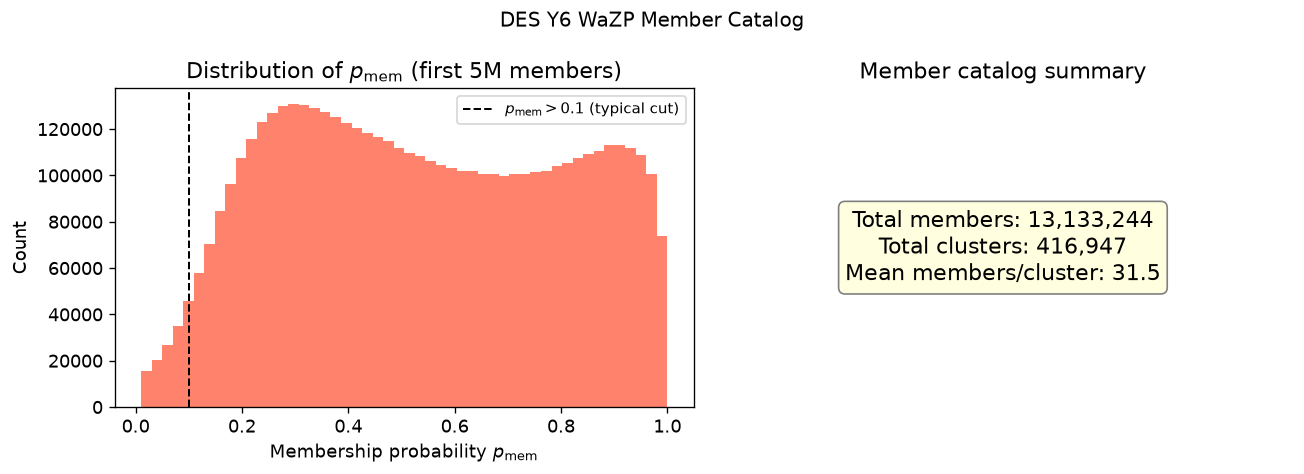

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.hist(pmem_sample, bins=50, color='tomato', edgecolor='none', alpha=0.8)
ax.set_xlabel('Membership probability $p_{\\rm mem}$')
ax.set_ylabel('Count')
ax.set_title('Distribution of $p_{\\rm mem}$ (first 5M members)')
ax.axvline(0.1, color='k', ls='--', lw=1.2, label='$p_{\\rm mem} > 0.1$ (typical cut)')
ax.legend(fontsize=9)

ax = axes[1]
ax.text(0.5, 0.5,
    f'Total members: {n_mem:,}\n'
    f'Total clusters: {len(cl):,}\n'
    f'Mean members/cluster: {n_mem/len(cl):.1f}',
    transform=ax.transAxes, ha='center', va='center', fontsize=13,
    bbox=dict(boxstyle='round', fc='lightyellow', ec='gray')
)
ax.set_axis_off()
ax.set_title('Member catalog summary')

plt.suptitle('DES Y6 WaZP Member Catalog', fontsize=12)
plt.tight_layout()
plt.show()

---
## 3 — DES Y3 redMaPPer Cluster Catalog

redMaPPer is a red-sequence cluster finder that produced 21,092 clusters in DES Y3.
The catalog includes a mass proxy `m200m` estimated from the richness–mass relation.

In [9]:
with h5py.File(f'{DATA}/y3_redmapper_v6.4.22+2_release.h5', 'r') as f:
    # Print HDF5 tree
    print('HDF5 structure:')
    def _show(name, obj):
        indent = '  ' * name.count('/')
        if isinstance(obj, h5py.Dataset):
            print(f'{indent}  [{name.split("/")[-1]:25s}]  shape={obj.shape}  {obj.dtype}')
        else:
            print(f'{indent}[GROUP] {name}')
    f.visititems(_show)

    # Load cluster data
    gc = f['catalog/cluster']
    rm_z    = gc['z_lambda'][:]
    rm_lam  = gc['lambda_chisq'][:]
    rm_ra   = gc['ra'][:]
    rm_dec  = gc['dec'][:]
    rm_m200 = gc['m200m'][:]
    rm_mask = gc['maskfrac'][:]
    # lgt20 selection index
    lgt20_idx = f['index/redmapper/lgt20/select'][:]

print(f'\nTotal clusters:           {len(rm_z):,}')
print(f'With lambda > 20 (lgt20): {len(lgt20_idx):,}')
print(f'z_lambda range:           {rm_z.min():.3f} – {rm_z.max():.3f}')
print(f'lambda range:             {rm_lam.min():.1f} – {rm_lam.max():.1f}')
print(f'm200m range (M☉):         {rm_m200.min():.2e} – {rm_m200.max():.2e}')

HDF5 structure:
[GROUP] catalog
  [GROUP] catalog/cluster
      [bcg_spec_z               ]  shape=(21092,)  >f4
      [dec                      ]  shape=(21092,)  >f8
      [id_cent                  ]  shape=(21092,)  ('>i8', (5,))
      [lambda(z)                ]  shape=(21092, 170)  float32
      [lambda(z)_xaxis          ]  shape=(21092, 170)  float32
      [lambda_chisq             ]  shape=(21092,)  >f4
      [lambda_chisq_e           ]  shape=(21092,)  >f4
      [m200m                    ]  shape=(21092,)  >f4
      [maskfrac                 ]  shape=(21092,)  >f4
      [mem_match_id             ]  shape=(21092,)  >i4
      [p_cen                    ]  shape=(21092,)  ('>f4', (5,))
      [ra                       ]  shape=(21092,)  >f8
      [scaleval                 ]  shape=(21092,)  >f4
      [z_lambda                 ]  shape=(21092,)  >f4
      [z_lambda_e               ]  shape=(21092,)  >f4
  [GROUP] catalog/cluster_members
      [dec                      ]  shape=(11693

In [10]:
# redMaPPer column descriptions
rm_col_desc = [
    ('z_lambda',          'Cluster photometric redshift from red-sequence fit'),
    ('z_lambda_e',        'Uncertainty on z_lambda'),
    ('lambda_chisq',      'Richness λ (weighted member count, chisq-optimised)'),
    ('lambda_chisq_e',    'Richness uncertainty'),
    ('m200m',             'Mass proxy M200m [M☉] from richness–mass relation'),
    ('ra / dec',          'Cluster sky position [deg]'),
    ('maskfrac',          'Fraction of cluster area masked'),
    ('scaleval',          'Scale value used for richness normalisation'),
    ('mem_match_id',      'ID linking to member catalog'),
    ('id_cent',           'IDs of top-5 central galaxy candidates'),
    ('p_cen',             'Centering probabilities for the 5 candidates'),
    ('bcg_spec_z',        'Spectroscopic redshift of the BCG if available'),
    ('lambda(z)',         '2D array: lambda as a function of photo-z (170 z bins)'),
    ('lambda(z)_xaxis',   'Redshift axis for the lambda(z) array'),
]
print(f'{"Column":<20}  Description')
print('-' * 75)
for col, desc in rm_col_desc:
    print(f'{col:<20}  {desc}')

Column                Description
---------------------------------------------------------------------------
z_lambda              Cluster photometric redshift from red-sequence fit
z_lambda_e            Uncertainty on z_lambda
lambda_chisq          Richness λ (weighted member count, chisq-optimised)
lambda_chisq_e        Richness uncertainty
m200m                 Mass proxy M200m [M☉] from richness–mass relation
ra / dec              Cluster sky position [deg]
maskfrac              Fraction of cluster area masked
scaleval              Scale value used for richness normalisation
mem_match_id          ID linking to member catalog
id_cent               IDs of top-5 central galaxy candidates
p_cen                 Centering probabilities for the 5 candidates
bcg_spec_z            Spectroscopic redshift of the BCG if available
lambda(z)             2D array: lambda as a function of photo-z (170 z bins)
lambda(z)_xaxis       Redshift axis for the lambda(z) array


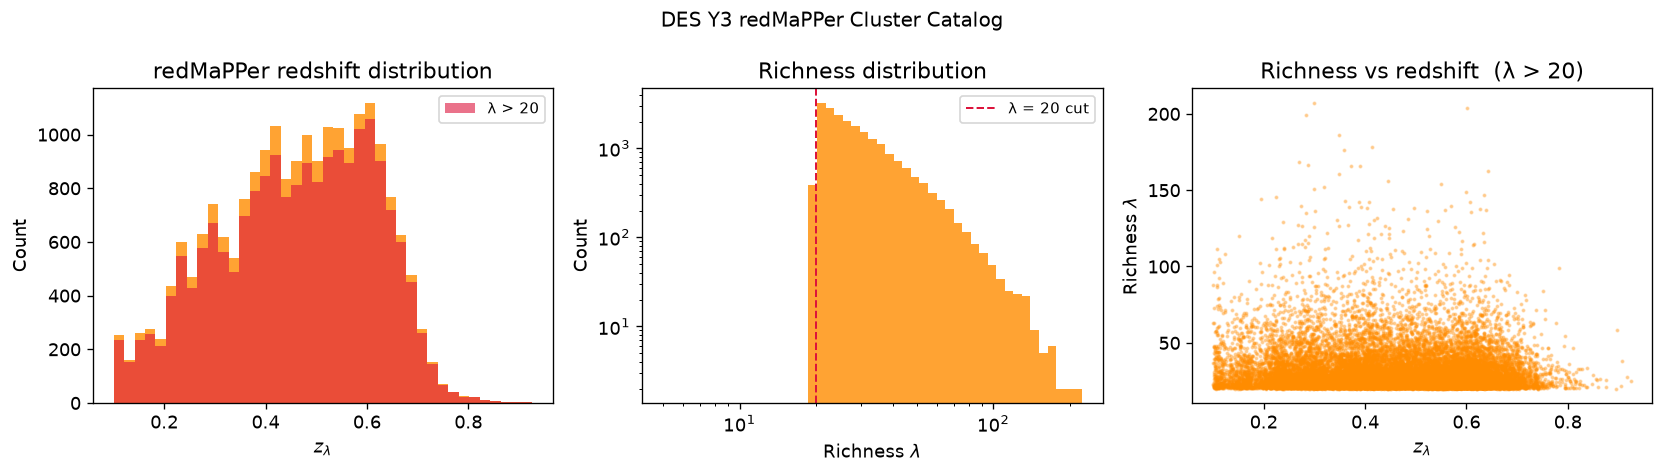

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

ax = axes[0]
ax.hist(rm_z, bins=40, color='darkorange', alpha=0.8, edgecolor='none')
ax.hist(rm_z[lgt20_idx], bins=40, color='crimson', alpha=0.6, edgecolor='none', label='λ > 20')
ax.set_xlabel(r'$z_{\lambda}$')
ax.set_ylabel('Count')
ax.set_title('redMaPPer redshift distribution')
ax.legend(fontsize=9)

ax = axes[1]
ax.hist(rm_lam, bins=np.logspace(np.log10(5), np.log10(rm_lam.max()+1), 50),
        color='darkorange', alpha=0.8, edgecolor='none')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'Richness $\lambda$')
ax.set_ylabel('Count')
ax.set_title('Richness distribution')
ax.axvline(20, color='crimson', ls='--', lw=1.2, label='λ = 20 cut')
ax.legend(fontsize=9)

ax = axes[2]
ax.scatter(rm_z[lgt20_idx], rm_lam[lgt20_idx], s=2, alpha=0.3, c='darkorange', rasterized=True)
ax.set_xlabel(r'$z_{\lambda}$')
ax.set_ylabel(r'Richness $\lambda$')
ax.set_title('Richness vs redshift  (λ > 20)')

plt.suptitle('DES Y3 redMaPPer Cluster Catalog', fontsize=12)
plt.tight_layout()
plt.savefig('figs/redmapper_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4 — DES Y3 Metacal Shape Catalog

The metacalibration shape catalog contains **399,263,026** objects measured on the DES Y3
co-add images in r, i, z bands. The HDF5 file has five groups:

| Group | Description |
|-------|-------------|
| `catalog/unsheared` | Main shape measurements. Contains position, shape, size, PSF, flags, response. |
| `catalog/sheared_1p` | Same objects re-measured after applying +Δγ₁ artificial shear |
| `catalog/sheared_1m` | Re-measured after −Δγ₁ shear |
| `catalog/sheared_2p` | Re-measured after +Δγ₂ shear |
| `catalog/sheared_2m` | Re-measured after −Δγ₂ shear |

The sheared catalogs are used to compute the **shear response** $R_{ij} = (e_i^+ - e_i^-) / (2\Delta\gamma)$,
which corrects for PSF smearing and noise bias in the ellipticity estimates.
The `unsheared` group also provides pre-computed diagonal response elements `R11`, `R22`.

In [12]:
# Print HDF5 structure (groups and datasets in unsheared only for brevity)
with h5py.File(f'{DATA}/DESY3_metacal_v03-004.h5', 'r') as f:
    print('Top-level groups:', list(f.keys()))
    print('catalog/ groups: ', list(f['catalog'].keys()))
    print(f'\nDatasets in catalog/unsheared  (N = {f["catalog/unsheared/ra"].shape[0]:,}):')
    for k in sorted(f['catalog/unsheared'].keys()):
        ds = f[f'catalog/unsheared/{k}']
        print(f'  {k:25s}  shape={ds.shape}  dtype={ds.dtype}')
    print(f'\nDatasets in catalog/sheared_1p (same shape, subset of columns):')
    for k in sorted(f['catalog/sheared_1p'].keys()):
        ds = f[f'catalog/sheared_1p/{k}']
        print(f'  {k:25s}  shape={ds.shape}  dtype={ds.dtype}')

Top-level groups: ['catalog']
catalog/ groups:  ['sheared_1m', 'sheared_1p', 'sheared_2m', 'sheared_2p', 'unsheared']

Datasets in catalog/unsheared  (N = 399,263,026):
  R11                        shape=(399263026,)  dtype=float64
  R12                        shape=(399263026,)  dtype=float64
  R21                        shape=(399263026,)  dtype=float64
  R22                        shape=(399263026,)  dtype=float64
  T                          shape=(399263026,)  dtype=>f8
  T_err                      shape=(399263026,)  dtype=>f8
  coadd_object_id            shape=(399263026,)  dtype=>i8
  covmat_0_1                 shape=(399263026,)  dtype=>f8
  covmat_1_1                 shape=(399263026,)  dtype=>f8
  covmat_2_2                 shape=(399263026,)  dtype=>f8
  dec                        shape=(399263026,)  dtype=>f8
  e_1                        shape=(399263026,)  dtype=>f8
  e_2                        shape=(399263026,)  dtype=>f8
  flags                      shape=(399263026,) 

In [13]:
# Column descriptions — unsheared group
mcal_desc = [
    ('coadd_object_id',  'DES coadd object unique identifier'),
    ('ra / dec',         'Sky position [deg]'),
    ('e_1 / e_2',        'Ellipticity components (distortion convention, not reduced shear)'),
    ('T',                'Object size: T = I_11 + I_22  [arcsec²] (sum of 2nd moments)'),
    ('T_err',            'Uncertainty on T'),
    ('size_ratio',       'T / T_psf — object size relative to PSF size (resolution factor)'),
    ('snr',              'S/N ratio of the metacal detection'),
    ('weight',           'Lensing weight (inverse variance from shape noise + measurement noise)'),
    ('flags',            'Quality flags; flags == 0 selects clean objects'),
    ('R11 / R22',        'Diagonal shear response (from sheared catalogs); R12/R21 ≈ 0'),
    ('R12 / R21',        'Off-diagonal response (typically small)'),
    ('psf_e1 / psf_e2',  'PSF ellipticity at object position'),
    ('psf_T',            'PSF size T_psf [arcsec²]'),
    ('mcal_psf_e1/e2',   'Metacal-specific PSF ellipticity estimate'),
    ('mcal_psf_T',       'Metacal-specific PSF size estimate'),
    ('mask_frac',        'Fraction of postage stamp masked'),
    ('flux_r/i/z',       'Photon flux in r, i, z bands [counts]'),
    ('flux_err_r/i/z',   'Flux uncertainty in r, i, z bands'),
    ('nimage_tot_r/i/z', 'Total number of single-epoch images contributing'),
    ('nimage_use_r/i/z', 'Number of images passing quality cuts'),
    ('covmat_0_1',       'Off-diagonal covariance between e_1 and e_2'),
    ('covmat_1_1',       'Variance of e_1'),
    ('covmat_2_2',       'Variance of e_2'),
]
print(f'{"Column":<25}  Description')
print('-' * 80)
for col, desc in mcal_desc:
    print(f'{col:<25}  {desc}')

Column                     Description
--------------------------------------------------------------------------------
coadd_object_id            DES coadd object unique identifier
ra / dec                   Sky position [deg]
e_1 / e_2                  Ellipticity components (distortion convention, not reduced shear)
T                          Object size: T = I_11 + I_22  [arcsec²] (sum of 2nd moments)
T_err                      Uncertainty on T
size_ratio                 T / T_psf — object size relative to PSF size (resolution factor)
snr                        S/N ratio of the metacal detection
weight                     Lensing weight (inverse variance from shape noise + measurement noise)
flags                      Quality flags; flags == 0 selects clean objects
R11 / R22                  Diagonal shear response (from sheared catalogs); R12/R21 ≈ 0
R12 / R21                  Off-diagonal response (typically small)
psf_e1 / psf_e2            PSF ellipticity at object position
psf

In [14]:
# ── Read a sequential 1M-object chunk from the middle of the catalog ────────
# Sequential reads are orders of magnitude faster than random access on a 291 GB file.
CHUNK = slice(100_000_000, 101_000_000)

with h5py.File(f'{DATA}/DESY3_metacal_v03-004.h5', 'r') as f:
    g = f['catalog/unsheared']
    flags = g['flags'][CHUNK]
    snr   = g['snr'][CHUNK]
    T     = g['T'][CHUNK]
    T_err = g['T_err'][CHUNK]
    sr    = g['size_ratio'][CHUNK]
    e1    = g['e_1'][CHUNK]
    e2    = g['e_2'][CHUNK]
    w     = g['weight'][CHUNK]
    ra    = g['ra'][CHUNK]
    dec   = g['dec'][CHUNK]
    R11   = g['R11'][CHUNK]
    R22   = g['R22'][CHUNK]
    psf_T = g['psf_T'][CHUNK]
    psf_e1= g['psf_e1'][CHUNK]
    psf_e2= g['psf_e2'][CHUNK]

# Standard DES Y3 metacal selection
sel = (flags == 0) & (snr > 10) & (snr < 1000) & (sr > 0.5) & (T > 0)

print(f'Chunk size:          {len(flags):,} objects')
print(f'After selection:     {sel.sum():,}  ({100*sel.mean():.1f}%)')
print(f'  flags == 0:        {(flags==0).sum():,}')
print(f'  + snr in [10,1000]:{((flags==0)&(snr>10)&(snr<1000)).sum():,}')
print(f'  + size_ratio > 0.5:{((flags==0)&(snr>10)&(snr<1000)&(sr>0.5)).sum():,}')
print(f'  + T > 0:           {sel.sum():,}')
print(f'\nSelected objects statistics:')
print(f'  RA  range: {ra[sel].min():.2f} – {ra[sel].max():.2f} deg')
print(f'  DEC range: {dec[sel].min():.2f} – {dec[sel].max():.2f} deg')
print(f'  e_1  mean ± std: {np.nanmean(e1[sel]):.5f} ± {np.nanstd(e1[sel]):.4f}')
print(f'  e_2  mean ± std: {np.nanmean(e2[sel]):.5f} ± {np.nanstd(e2[sel]):.4f}')
print(f'  R11  mean:       {np.nanmean(R11[sel]):.4f}')
print(f'  R22  mean:       {np.nanmean(R22[sel]):.4f}')
print(f'  SNR  median:     {np.nanmedian(snr[sel]):.1f}')
print(f'  T    median:     {np.nanmedian(T[sel]):.4f} arcsec²')
print(f'  size_ratio med:  {np.nanmedian(sr[sel]):.3f}')
print(f'  weight mean:     {np.nanmean(w[sel]):.2f}')

Chunk size:          1,000,000 objects
After selection:     236,511  (23.7%)
  flags == 0:        878,909
  + snr in [10,1000]:564,274
  + size_ratio > 0.5:236,511
  + T > 0:           236,511

Selected objects statistics:
  RA  range: 60.07 – 70.00 deg
  DEC range: -64.94 – -60.82 deg
  e_1  mean ± std: -0.00014 ± 0.2067
  e_2  mean ± std: -0.00107 ± 0.2083
  R11  mean:       0.6606
  R22  mean:       0.6618
  SNR  median:     23.7
  T    median:     0.4625 arcsec²
  size_ratio med:  1.121
  weight mean:     33.50


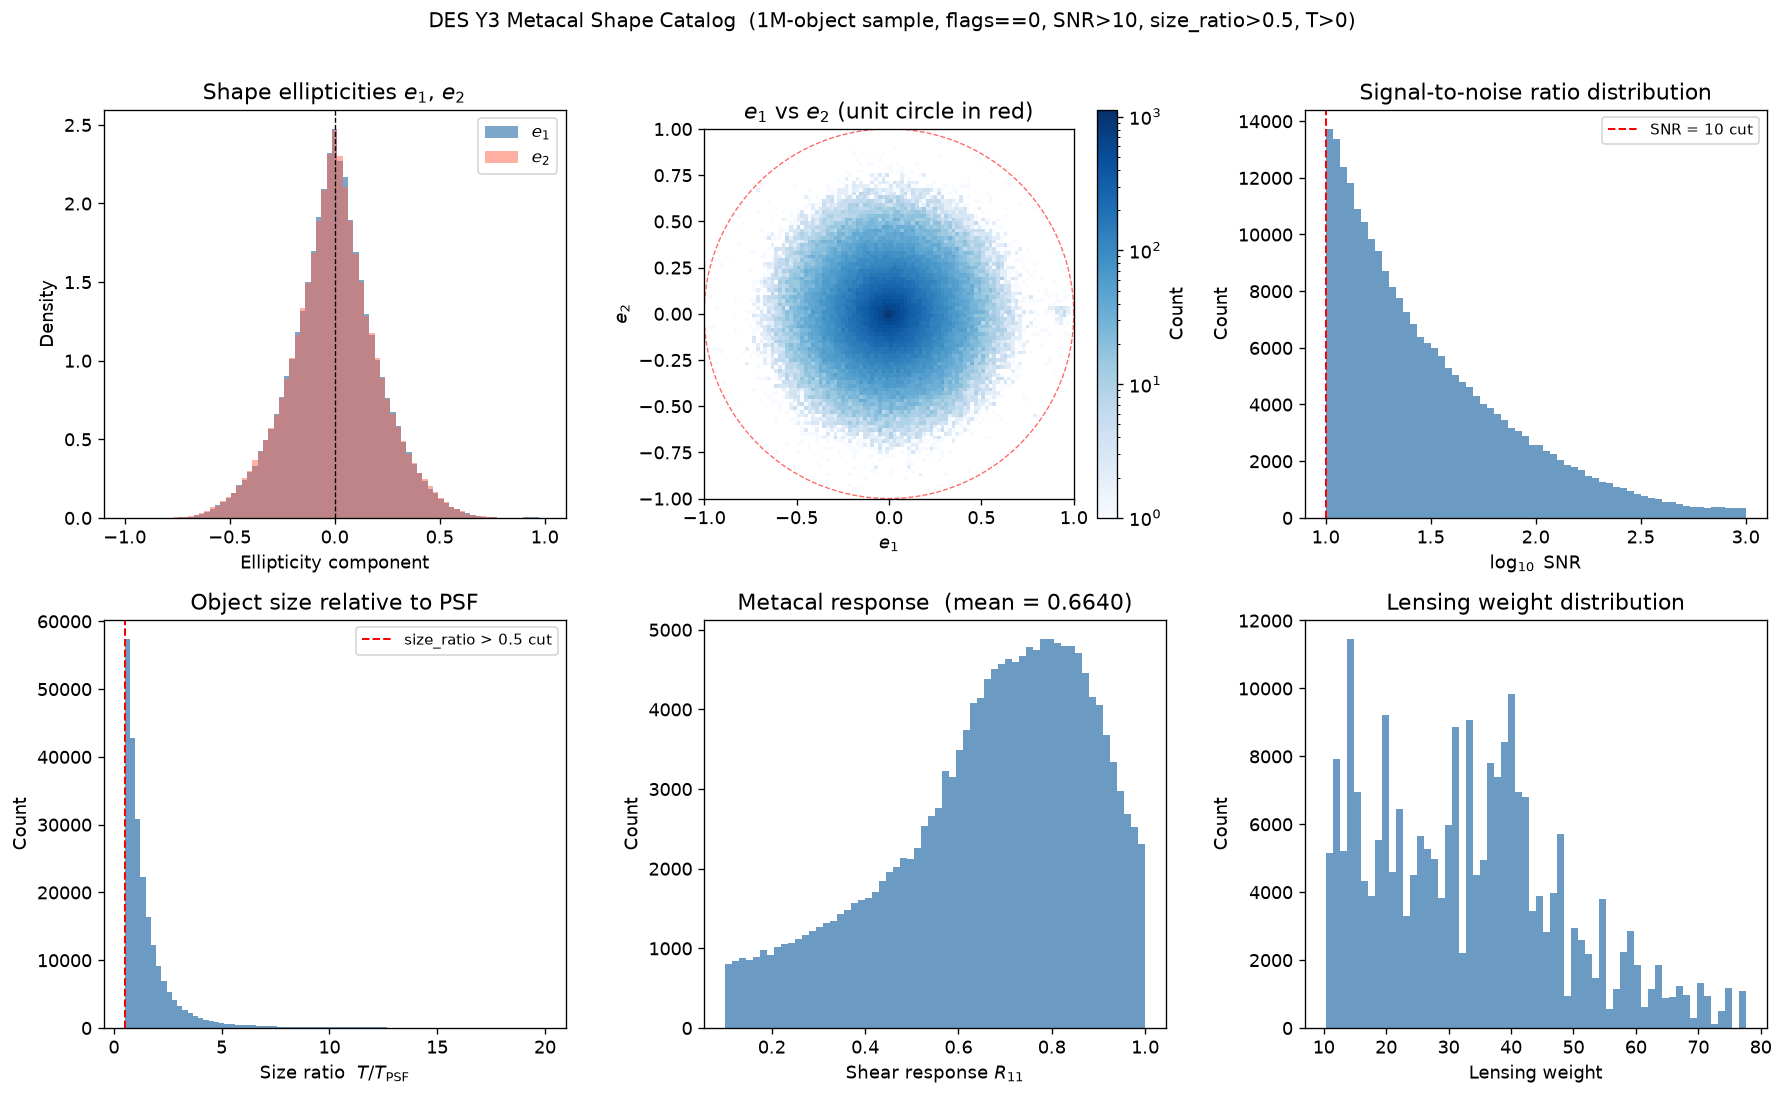

In [15]:
# ── Shape catalog statistics plots ───────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

e1s = e1[sel]
e2s = e2[sel]
snrs = snr[sel]
srs  = sr[sel]
Ts   = T[sel]
ws   = w[sel]
R11s = R11[sel]

# 1. Ellipticity e_1 and e_2 distributions
ax = axes[0, 0]
bins_e = np.linspace(-1, 1, 80)
ax.hist(e1s[np.isfinite(e1s)], bins=bins_e, color='steelblue',
        alpha=0.7, density=True, label='$e_1$')
ax.hist(e2s[np.isfinite(e2s)], bins=bins_e, color='tomato',
        alpha=0.5, density=True, label='$e_2$')
ax.set_xlabel('Ellipticity component')
ax.set_ylabel('Density')
ax.set_title('Shape ellipticities $e_1$, $e_2$')
ax.legend(fontsize=10)
ax.axvline(0, color='k', lw=0.8, ls='--')

# 2. e_1 vs e_2 scatter (2D histogram)
ax = axes[0, 1]
fin = np.isfinite(e1s) & np.isfinite(e2s)
h2, xe2, ye2, im = ax.hist2d(
    e1s[fin], e2s[fin],
    bins=100, range=[[-1, 1], [-1, 1]],
    cmap='Blues', norm=mcolors.LogNorm()
)
plt.colorbar(im, ax=ax, label='Count')
# Draw unit circle
theta = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), 'r--', lw=0.8, alpha=0.6)
ax.set_xlabel('$e_1$'); ax.set_ylabel('$e_2$')
ax.set_title('$e_1$ vs $e_2$ (unit circle in red)')
ax.set_aspect('equal')

# 3. SNR distribution
ax = axes[0, 2]
ax.hist(np.log10(snrs[snrs > 0]), bins=60, color='steelblue', alpha=0.8, edgecolor='none')
ax.set_xlabel('$\\log_{10}$ SNR')
ax.set_ylabel('Count')
ax.set_title('Signal-to-noise ratio distribution')
ax.axvline(np.log10(10), color='r', ls='--', lw=1.2, label='SNR = 10 cut')
ax.legend(fontsize=9)

# 4. Size ratio (T/T_PSF) distribution
ax = axes[1, 0]
ax.hist(srs[srs < 20], bins=80, color='steelblue', alpha=0.8, edgecolor='none')
ax.set_xlabel('Size ratio  $T / T_{\\rm PSF}$')
ax.set_ylabel('Count')
ax.set_title('Object size relative to PSF')
ax.axvline(0.5, color='r', ls='--', lw=1.2, label='size_ratio > 0.5 cut')
ax.legend(fontsize=9)

# 5. Shear response R11 distribution
ax = axes[1, 1]
R11_fin = R11s[np.isfinite(R11s) & (R11s > 0.1) & (R11s < 1.0)]
ax.hist(R11_fin, bins=60, color='steelblue', alpha=0.8, edgecolor='none')
ax.set_xlabel('Shear response $R_{11}$')
ax.set_ylabel('Count')
ax.set_title(f'Metacal response  (mean = {R11_fin.mean():.4f})')

# 6. Lensing weight distribution
ax = axes[1, 2]
ax.hist(ws, bins=60, color='steelblue', alpha=0.8, edgecolor='none')
ax.set_xlabel('Lensing weight')
ax.set_ylabel('Count')
ax.set_title('Lensing weight distribution')

plt.suptitle(
    'DES Y3 Metacal Shape Catalog  '
    '(1M-object sample, flags==0, SNR>10, size_ratio>0.5, T>0)',
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.savefig('figs/metacal_shape_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

### Metacal shape catalog sky distribution — Aitoff projection (healpy)

Unlike the stats above (deliberately limited to one fast sequential 1M-object
chunk), a sky-distribution plot needs real spatial coverage: a single
contiguous chunk from this file is a narrow RA/Dec strip, not the survey
footprint (the catalog is stored in spatially-tiled order). So this scans
the **entire** 399M-object catalog chunk-by-chunk (reading only the light
columns needed for selection + position, never materializing the full
catalog at once) and accumulates a HEALPix count map — the only way to get
an accurate footprint. Takes about 2 minutes.

Full-catalog scan: 126,934,514 selected objects  (124s)


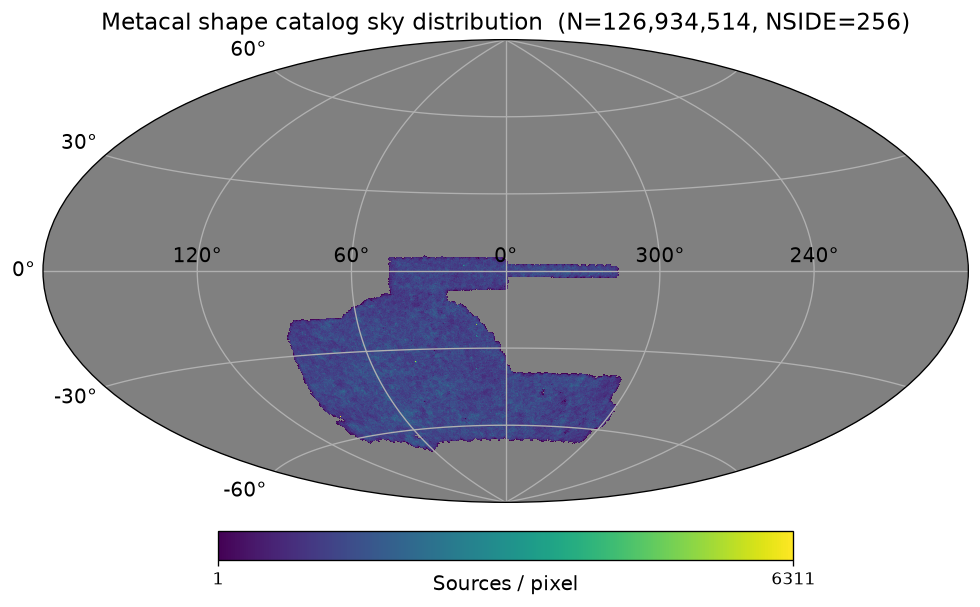

In [16]:
NSIDE_SHAPE = 256
npix_shape = hp.nside2npix(NSIDE_SHAPE)
counts_s = np.zeros(npix_shape)
n_sel_total = 0
CHUNK_SIZE = 1_000_000  # matches the file's own HDF5 chunk size (aligned = fast)

t0 = time.time()
with h5py.File(f'{DATA}/DESY3_metacal_v03-004.h5', 'r') as f_full:
    g_full = f_full['catalog/unsheared']
    n_total_mcal = g_full['ra'].shape[0]
    n_chunks = -(-n_total_mcal // CHUNK_SIZE)
    for i in range(n_chunks):
        s = slice(i * CHUNK_SIZE, min((i + 1) * CHUNK_SIZE, n_total_mcal))
        flags_c = g_full['flags'][s]; snr_c = g_full['snr'][s]
        T_c = g_full['T'][s]; sr_c = g_full['size_ratio'][s]
        m = (flags_c == 0) & (snr_c > 10) & (snr_c < 1000) & (sr_c > 0.5) & (T_c > 0)
        if not m.any():
            continue
        theta_c = np.radians(90.0 - g_full['dec'][s][m])
        phi_c   = np.radians(g_full['ra'][s][m])
        counts_s += np.bincount(hp.ang2pix(NSIDE_SHAPE, theta_c, phi_c), minlength=npix_shape)
        n_sel_total += int(m.sum())

print(f'Full-catalog scan: {n_sel_total:,} selected objects  ({time.time()-t0:.0f}s)')
counts_s[counts_s == 0] = np.nan

projview(
    counts_s,
    projection_type='aitoff',
    coord=['C'],
    graticule=True, graticule_labels=True,
    unit='Sources / pixel',
    cmap='viridis',
    title=f'Metacal shape catalog sky distribution  (N={n_sel_total:,}, NSIDE={NSIDE_SHAPE})',
)
plt.savefig('figs/metacal_sky_aitoff.pdf', bbox_inches='tight')
plt.show()

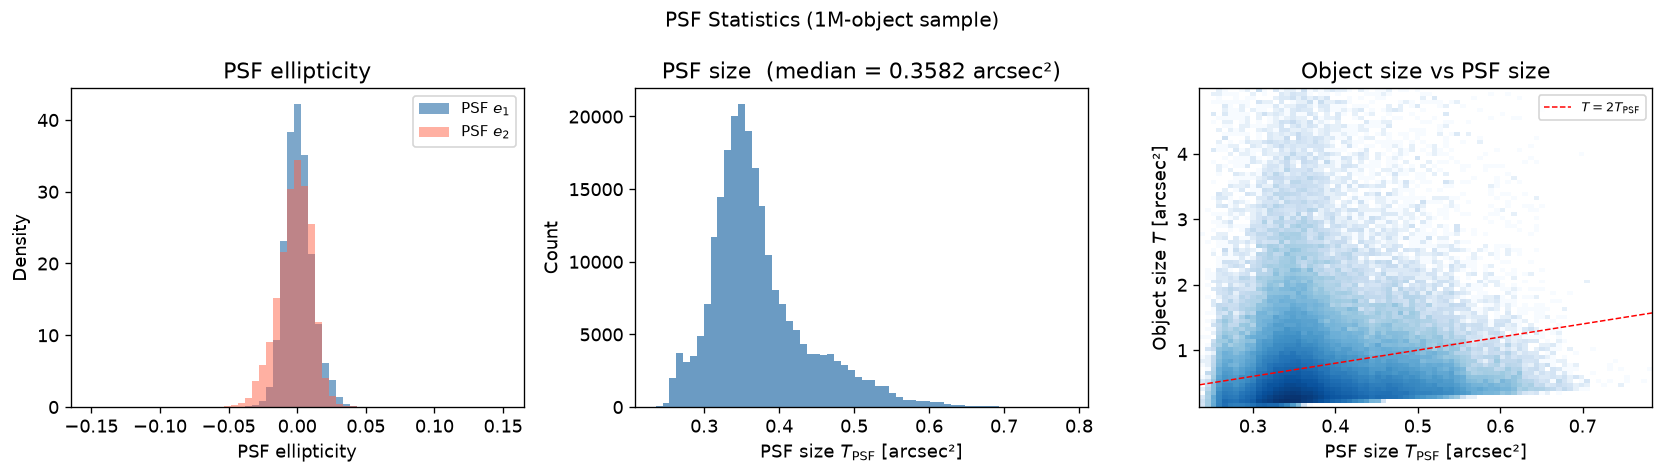

In [17]:
# ── PSF statistics ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

psf_e1s = psf_e1[sel]
psf_e2s = psf_e2[sel]
psf_Ts  = psf_T[sel]

ax = axes[0]
fin_psf = np.isfinite(psf_e1s) & np.isfinite(psf_e2s)
bins_pe = np.linspace(-0.15, 0.15, 60)
ax.hist(psf_e1s[fin_psf], bins=bins_pe, color='steelblue', alpha=0.7, density=True, label='PSF $e_1$')
ax.hist(psf_e2s[fin_psf], bins=bins_pe, color='tomato', alpha=0.5, density=True, label='PSF $e_2$')
ax.set_xlabel('PSF ellipticity'); ax.set_ylabel('Density')
ax.set_title('PSF ellipticity')
ax.legend(fontsize=9)

ax = axes[1]
fin_pT = np.isfinite(psf_Ts) & (psf_Ts > 0) & (psf_Ts < 1)
ax.hist(psf_Ts[fin_pT], bins=60, color='steelblue', alpha=0.8)
ax.set_xlabel('PSF size $T_{\\rm PSF}$ [arcsec²]')
ax.set_ylabel('Count')
ax.set_title(f'PSF size  (median = {np.nanmedian(psf_Ts[fin_pT]):.4f} arcsec²)')

ax = axes[2]
fin_sr = np.isfinite(Ts) & np.isfinite(psf_Ts) & (psf_Ts > 0) & (psf_Ts < 1) & (Ts > 0) & (Ts < 5)
ax.hist2d(
    psf_Ts[fin_sr], Ts[fin_sr],
    bins=80, cmap='Blues', norm=mcolors.LogNorm()
)
ax.set_xlabel('PSF size $T_{\\rm PSF}$ [arcsec²]')
ax.set_ylabel('Object size $T$ [arcsec²]')
ax.set_title('Object size vs PSF size')
# diagonal: T = T_psf (PSF-like objects below cut)
xlim = ax.get_xlim()
ax.plot(xlim, [2*xlim[0], 2*xlim[1]], 'r--', lw=0.9, label='$T = 2 T_{\\rm PSF}$')
ax.legend(fontsize=8)

plt.suptitle('PSF Statistics (1M-object sample)', fontsize=12)
plt.tight_layout()
plt.savefig('figs/metacal_psf_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# ── Summary ──────────────────────────────────────────────────────────────────
print('=== Dataset Summary ===')
print()
print('DES Y6 WaZP Clusters')
print(f'  {len(cl):,} total  |  {len(cosmo):,} in cosmological sample')
print(f'  z_phot: {cl["ZPHOT"].min():.3f} – {cl["ZPHOT"].max():.3f}')
print(f'  N_gals: {cl["NGALS"].min():.0f} – {cl["NGALS"].max():.0f}')
print()
print('DES Y3 redMaPPer Clusters')
print(f'  {len(rm_z):,} total  |  {len(lgt20_idx):,} with λ > 20')
print(f'  z_lambda: {rm_z.min():.3f} – {rm_z.max():.3f}')
print(f'  λ: {rm_lam.min():.0f} – {rm_lam.max():.0f}')
print()
print('DES Y3 Metacal Shape Catalog')
print(f'  399,263,026 total objects')
print(f'  ~23% pass standard cuts (flags==0, SNR>10, size_ratio>0.5, T>0)')
print(f'  Groups: unsheared + sheared_1p/1m/2p/2m (for response computation)')
print(f'  Mean shear response R̄11 ≈ 0.66  (from selected objects in sample chunk)')

=== Dataset Summary ===

DES Y6 WaZP Clusters
  416,947 total  |  301,406 in cosmological sample
  z_phot: 0.027 – 1.317
  N_gals: 5 – 309

DES Y3 redMaPPer Clusters
  21,092 total  |  19,388 with λ > 20
  z_lambda: 0.100 – 0.926
  λ: 20 – 222

DES Y3 Metacal Shape Catalog
  399,263,026 total objects
  ~23% pass standard cuts (flags==0, SNR>10, size_ratio>0.5, T>0)
  Groups: unsheared + sheared_1p/1m/2p/2m (for response computation)
  Mean shear response R̄11 ≈ 0.66  (from selected objects in sample chunk)
